# Complete Controlled Comparison: 2025 Phishing Framework vs Baseline BERT

**Goal:** Use the same Kaggle dataset and the same fixed split to compare:

1. **Baseline BERT** — standard `bert-base-uncased` sequence classification.
2. **2025-style Hybrid** — BERT + BatchNorm + Multi-Head Attention + CNN-1D + BiGRU + Dropout/Dense.
3. **Optional MGO tuning** — a small validation-set hyperparameter search.

**Important:** This is a transparent reference reproduction of the 2025 paper's methodology, not the authors' official code. The paper does not publish enough details to guarantee exact replication.

Paper: https://www.nature.com/articles/s41598-025-20668-5  
Dataset: https://www.kaggle.com/datasets/subhajournal/phishingemails


## 0. Runtime
In Google Colab select **Runtime → Change runtime type → T4 GPU** before training.


In [ ]:
!pip -q install -U transformers accelerate kagglehub scikit-learn pandas matplotlib scipy statsmodels pymetaheuristic


In [ ]:
import os, gc, json, time, math, random, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from statsmodels.stats.contingency_tables import mcnemar
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
if torch.cuda.is_available(): print('GPU:', torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


## 1. Configuration

These settings define **your controlled protocol**. The 2025 paper does not clearly publish its exact split/seed/max token length, so do not claim these are the authors' exact settings.


In [ ]:
PROJECT_DIR = Path('/content/phishing_project')
DATA_DIR = PROJECT_DIR/'data'
RESULTS_DIR = PROJECT_DIR/'results'
MODEL_DIR = PROJECT_DIR/'models'
for d in [DATA_DIR, RESULTS_DIR, MODEL_DIR]: d.mkdir(parents=True, exist_ok=True)

MODEL_NAME = 'google-bert/bert-base-uncased'
MAX_LENGTH = 256
TRAIN_BATCH = 4
EVAL_BATCH = 8
EPOCHS = 3
LR = 2e-5
WEIGHT_DECAY = 0.01
DROPOUT = 0.30
CNN_FILTERS = 128
GRU_HIDDEN = 128
ATTN_HEADS = 8
GRAD_ACCUM = 4
REMOVE_DUPLICATES = False  # False is closer to the paper because duplicate removal is not clearly reported.
FREEZE_BERT = False

print('Config loaded')


Config loaded


## 2. Download the same Kaggle dataset identified in the 2025 paper


In [ ]:
import kagglehub
try:
    path = kagglehub.dataset_download('subhajournal/phishingemails', output_dir=str(DATA_DIR))
    print('Downloaded to:', path)
except Exception as e:
    print('Automatic download failed:', e)
    print('Fallback: download manually from https://www.kaggle.com/datasets/subhajournal/phishingemails and upload the CSV into /content/phishing_project/data/')


100%|██████████| 18.0M/18.0M [00:01<00:00, 17.9MB/s]

Extracting files...


Downloaded to: /content/phishing_project/data


In [ ]:
csv_files = list(DATA_DIR.rglob('*.csv'))
print('CSV files:', csv_files)
if not csv_files:
    raise FileNotFoundError('No CSV found. Upload the Kaggle CSV into /content/phishing_project/data/ and rerun this cell.')
CSV_PATH = max(csv_files, key=lambda p: p.stat().st_size)
df_raw = pd.read_csv(CSV_PATH)
print('Selected:', CSV_PATH)
print('Original shape:', df_raw.shape)
print('Columns:', df_raw.columns.tolist())
display(df_raw.head())


CSV files: [PosixPath('/content/phishing_project/data/Phishing_Email.csv')]
Selected: /content/phishing_project/data/Phishing_Email.csv
Original shape: (18650, 3)
Columns: ['Unnamed: 0', 'Email Text', 'Email Type']


,Unnamed: 0,Email Text,Email Type
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,1,the other side of * galicismos * * galicismo *...,Safe Email
2,2,re : equistar deal tickets are you still avail...,Safe Email
3,3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,4,software at incredibly low prices ( 86 % lower...,Phishing Email


## 3. Dataset audit and preprocessing


In [ ]:
def find_col(cols, candidates):
    m = {str(c).strip().lower(): c for c in cols}
    for cand in candidates:
        if cand.lower() in m: return m[cand.lower()]
    return None

TEXT_COL = find_col(df_raw.columns, ['Email Text','email_text','text','body','message','content'])
LABEL_COL = find_col(df_raw.columns, ['Email Type','email_type','label','class','type','category'])
if TEXT_COL is None or LABEL_COL is None:
    raise ValueError(f'Could not identify text/label columns. Available: {df_raw.columns.tolist()}')

print('Text column:', TEXT_COL)
print('Label column:', LABEL_COL)
print('\nOriginal labels:')
print(df_raw[LABEL_COL].value_counts(dropna=False))
print('\nMissing values:')
print(df_raw[[TEXT_COL,LABEL_COL]].isna().sum())
print('Exact duplicate rows:', df_raw.duplicated().sum())
print('Duplicate texts:', df_raw.duplicated(subset=[TEXT_COL]).sum())


Text column: Email Text
Label column: Email Type

Original labels:
Email Type
Safe Email        11322
Phishing Email     7328
Name: count, dtype: int64

Missing values:
Email Text    16
Email Type     0
dtype: int64
Exact duplicate rows: 0
Duplicate texts: 1112


In [ ]:
df = df_raw[[TEXT_COL, LABEL_COL]].copy()
df.columns = ['text','label_original']
original_n = len(df)
df = df.dropna(subset=['text','label_original']).copy()
df['text'] = df['text'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
df = df[df['text'].str.len() > 0].copy()
after_empty_n = len(df)

if REMOVE_DUPLICATES:
    before = len(df)
    df = df.drop_duplicates(subset=['text']).copy()
    removed_dupes = before-len(df)
else:
    removed_dupes = 0

def map_label(v):
    s = str(v).strip().lower()
    if 'phish' in s: return 1
    if 'safe' in s or 'legit' in s or s == 'ham': return 0
    if s in {'1','malicious'}: return 1
    if s == '0': return 0
    return np.nan

df['label'] = df['label_original'].map(map_label)
if df['label'].isna().any():
    print('Unmapped labels:')
    print(df.loc[df['label'].isna(),'label_original'].value_counts())
    raise ValueError('Please update map_label() for the unmapped labels.')
df['label'] = df['label'].astype(int)
df['word_count'] = df['text'].str.split().str.len()

summary = pd.DataFrame({
    'item':['original_records','after_empty_removal','duplicates_removed','final_records','safe_emails','phishing_emails','mean_word_count','median_word_count','max_word_count'],
    'value':[original_n,after_empty_n,removed_dupes,len(df),int((df.label==0).sum()),int((df.label==1).sum()),round(df.word_count.mean(),2),round(df.word_count.median(),2),int(df.word_count.max())]
})
display(summary)
summary.to_csv(RESULTS_DIR/'dataset_summary.csv', index=False)


,item,value
0,original_records,18650.00
1,after_empty_removal,18631.00
2,duplicates_removed,0.00
3,final_records,18631.00
4,safe_emails,11322.00
5,phishing_emails,7309.00
6,mean_word_count,535.27
7,median_word_count,160.00
8,max_word_count,3527576.00


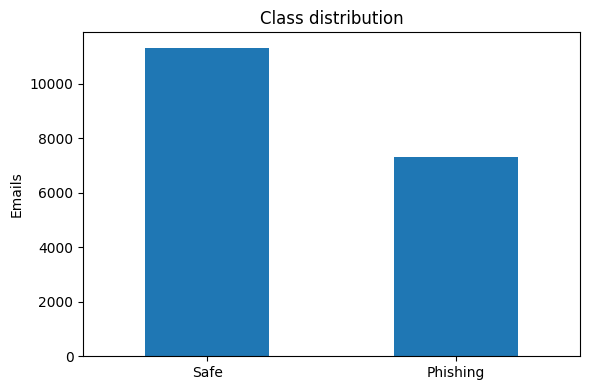

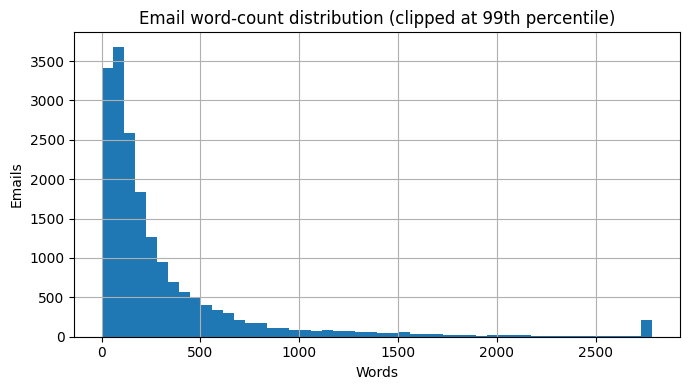

In [ ]:
counts = df['label'].value_counts().sort_index()
plt.figure(figsize=(6,4)); counts.index=['Safe','Phishing']; counts.plot(kind='bar')
plt.title('Class distribution'); plt.ylabel('Emails'); plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(RESULTS_DIR/'class_distribution.png',dpi=300); plt.show()

plt.figure(figsize=(7,4)); df['word_count'].clip(upper=df['word_count'].quantile(.99)).hist(bins=50)
plt.title('Email word-count distribution (clipped at 99th percentile)'); plt.xlabel('Words'); plt.ylabel('Emails'); plt.tight_layout(); plt.savefig(RESULTS_DIR/'length_distribution.png',dpi=300); plt.show()


## 4. Fixed train / validation / test split used by BOTH models


In [ ]:
train_df, temp_df = train_test_split(df[['text','label']], test_size=0.20, stratify=df['label'], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED)
train_df=train_df.reset_index(drop=True); val_df=val_df.reset_index(drop=True); test_df=test_df.reset_index(drop=True)
print('Train/Val/Test:', len(train_df), len(val_df), len(test_df))
print('Test class counts:\n', test_df.label.value_counts().sort_index())
train_df.to_csv(DATA_DIR/'train.csv',index=False); val_df.to_csv(DATA_DIR/'validation.csv',index=False); test_df.to_csv(DATA_DIR/'test.csv',index=False)


Train/Val/Test: 14904 1863 1864
Test class counts:
 label
0    1133
1     731
Name: count, dtype: int64


## 5. Tokenizer and dataset class


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
class EmailDataset(Dataset):
    def __init__(self, frame):
        self.texts=frame.text.tolist(); self.labels=frame.label.tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self,i):
        enc=tokenizer(self.texts[i], truncation=True, padding='max_length', max_length=MAX_LENGTH, return_tensors='pt')
        return {'input_ids':enc['input_ids'].squeeze(0), 'attention_mask':enc['attention_mask'].squeeze(0), 'label':torch.tensor(self.labels[i],dtype=torch.long)}

def make_loaders(train_batch=TRAIN_BATCH, eval_batch=EVAL_BATCH):
    g=torch.Generator(); g.manual_seed(SEED)
    return (
        DataLoader(EmailDataset(train_df), batch_size=train_batch, shuffle=True, generator=g, num_workers=2, pin_memory=True),
        DataLoader(EmailDataset(val_df), batch_size=eval_batch, shuffle=False, num_workers=2, pin_memory=True),
        DataLoader(EmailDataset(test_df), batch_size=eval_batch, shuffle=False, num_workers=2, pin_memory=True),
    )
train_loader,val_loader,test_loader=make_loaders()


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

## 6. Shared train / evaluate functions


In [ ]:
def metrics_from_preds(y_true,y_pred):
    return {
        'accuracy':float(accuracy_score(y_true,y_pred)),
        'precision':float(precision_score(y_true,y_pred,zero_division=0)),
        'recall':float(recall_score(y_true,y_pred,zero_division=0)),
        'f1':float(f1_score(y_true,y_pred,zero_division=0)),
    }

def evaluate_model(model, loader):
    model.eval(); ys=[]; ps=[]; probs=[]
    with torch.no_grad():
        for b in loader:
            ids=b['input_ids'].to(DEVICE); mask=b['attention_mask'].to(DEVICE); y=b['label'].to(DEVICE)
            out=model(input_ids=ids, attention_mask=mask)
            logits=out.logits if hasattr(out,'logits') else out
            pr=torch.softmax(logits,dim=1)
            pred=pr.argmax(1)
            ys.extend(y.cpu().numpy()); ps.extend(pred.cpu().numpy()); probs.extend(pr[:,1].cpu().numpy())
    m=metrics_from_preds(ys,ps)
    return m, np.array(ys), np.array(ps), np.array(probs)

def train_model(model, train_loader, val_loader, name, epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY):
    model=model.to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=weight_decay)
    total_steps=math.ceil(len(train_loader)/GRAD_ACCUM)*epochs
    scheduler=get_linear_schedule_with_warmup(optimizer,num_warmup_steps=int(.1*total_steps),num_training_steps=total_steps)
    scaler=torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
    loss_fn=nn.CrossEntropyLoss()
    best_f1=-1; best_state=None; history=[]; start=time.time()
    for epoch in range(1,epochs+1):
        model.train(); optimizer.zero_grad(set_to_none=True); running=0.0
        for step,b in enumerate(train_loader,1):
            ids=b['input_ids'].to(DEVICE); mask=b['attention_mask'].to(DEVICE); y=b['label'].to(DEVICE)
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                out=model(input_ids=ids,attention_mask=mask)
                logits=out.logits if hasattr(out,'logits') else out
                loss=loss_fn(logits,y)/GRAD_ACCUM
            scaler.scale(loss).backward(); running += loss.item()*GRAD_ACCUM
            if step%GRAD_ACCUM==0 or step==len(train_loader):
                scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
                scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True); scheduler.step()
        val_m,_,_,_=evaluate_model(model,val_loader)
        row={'epoch':epoch,'train_loss':running/len(train_loader),**{f'val_{k}':v for k,v in val_m.items()}}
        history.append(row); print(name,row)
        if val_m['f1']>best_f1:
            best_f1=val_m['f1']; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    model.load_state_dict(best_state); model.to(DEVICE)
    elapsed=(time.time()-start)/60
    pd.DataFrame(history).to_csv(RESULTS_DIR/f'training_history_{name}.csv',index=False)
    return model, elapsed

def save_eval(name, model, loader, elapsed_min):
    m,y,p,prob=evaluate_model(model,loader); m['training_time_min']=float(elapsed_min)
    with open(RESULTS_DIR/f'{name}_metrics.json','w') as f: json.dump(m,f,indent=2)
    pred_df=test_df.copy(); pred_df['prediction']=p; pred_df['phishing_probability']=prob; pred_df['correct']=pred_df.label==pred_df.prediction
    pred_df.to_csv(RESULTS_DIR/f'{name}_predictions.csv',index=False)
    cm=confusion_matrix(y,p)
    disp=ConfusionMatrixDisplay(cm,display_labels=['Safe','Phishing']); disp.plot(values_format='d'); plt.title(name.replace('_',' ').title()); plt.tight_layout(); plt.savefig(RESULTS_DIR/f'{name}_confusion_matrix.png',dpi=300); plt.show()
    print(classification_report(y,p,target_names=['Safe','Phishing'],digits=4)); print(m)
    return m,y,p,prob,cm


## 7. MODEL A — Baseline BERT


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


baseline_bert {'epoch': 1, 'train_loss': 0.17458902542557822, 'val_accuracy': 0.9677938808373591, 'val_precision': 0.9602194787379973, 'val_recall': 0.957592339261286, 'val_f1': 0.958904109589041}
baseline_bert {'epoch': 2, 'train_loss': 0.04263181743670457, 'val_accuracy': 0.9715512614063339, 'val_precision': 0.937984496124031, 'val_recall': 0.9931600547195623, 'val_f1': 0.9647840531561461}
baseline_bert {'epoch': 3, 'train_loss': 0.023530262367928854, 'val_accuracy': 0.9742351046698873, 'val_precision': 0.9559412550066756, 'val_recall': 0.9794801641586868, 'val_f1': 0.9675675675675676}


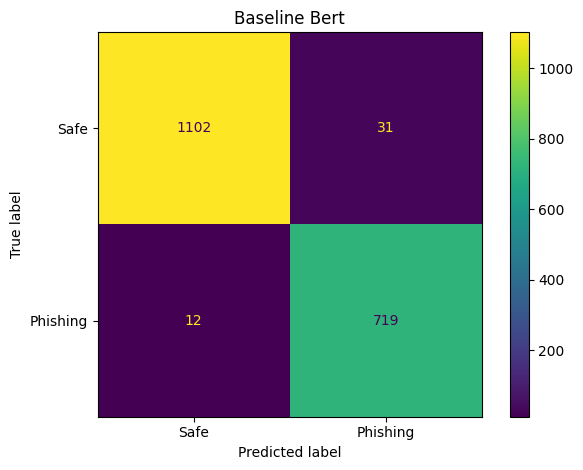

              precision    recall  f1-score   support

        Safe     0.9892    0.9726    0.9809      1133
    Phishing     0.9587    0.9836    0.9710       731

    accuracy                         0.9769      1864
   macro avg     0.9739    0.9781    0.9759      1864
weighted avg     0.9772    0.9769    0.9770      1864

{'accuracy': 0.976931330472103, 'precision': 0.9586666666666667, 'recall': 0.9835841313269493, 'f1': 0.9709655638082377, 'training_time_min': 16.608722627162933}


In [ ]:
baseline_model=AutoModelForSequenceClassification.from_pretrained(MODEL_NAME,num_labels=2)
if FREEZE_BERT:
    for p in baseline_model.bert.parameters(): p.requires_grad=False
baseline_model, baseline_time=train_model(baseline_model,train_loader,val_loader,'baseline_bert')
baseline_metrics,y_true,baseline_pred,baseline_prob,baseline_cm=save_eval('baseline_bert',baseline_model,test_loader,baseline_time)


## 8. MODEL B — 2025-style Hybrid

The paper mentions BERT pooled output and then attention/CNN/GRU. A one-vector pooled output is not naturally a token sequence, so this transparent implementation uses BERT's `last_hidden_state` token sequence. Record this as an implementation interpretation, not hidden knowledge of the authors' code.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


hybrid_fixed {'epoch': 1, 'train_loss': 0.2561731365855765, 'val_accuracy': 0.9570585077831455, 'val_precision': 0.9125475285171103, 'val_recall': 0.9849521203830369, 'val_f1': 0.9473684210526315}
hybrid_fixed {'epoch': 2, 'train_loss': 0.10126335297421749, 'val_accuracy': 0.9699409554482018, 'val_precision': 0.9530201342281879, 'val_recall': 0.9712722298221614, 'val_f1': 0.962059620596206}
hybrid_fixed {'epoch': 3, 'train_loss': 0.07389857461231086, 'val_accuracy': 0.9720880300590445, 'val_precision': 0.952063914780293, 'val_recall': 0.9781121751025992, 'val_f1': 0.9649122807017544}


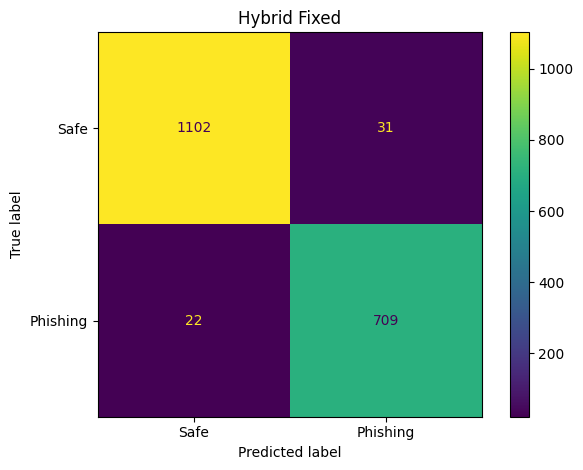

              precision    recall  f1-score   support

        Safe     0.9804    0.9726    0.9765      1133
    Phishing     0.9581    0.9699    0.9640       731

    accuracy                         0.9716      1864
   macro avg     0.9693    0.9713    0.9702      1864
weighted avg     0.9717    0.9716    0.9716      1864

{'accuracy': 0.9715665236051502, 'precision': 0.9581081081081081, 'recall': 0.9699042407660738, 'f1': 0.9639700883752549, 'training_time_min': 17.658651928106945}


In [ ]:
class Hybrid2025(nn.Module):
    def __init__(self, heads=ATTN_HEADS, cnn_filters=CNN_FILTERS, gru_hidden=GRU_HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.bert=AutoModel.from_pretrained(MODEL_NAME)
        h=self.bert.config.hidden_size
        self.bn=nn.BatchNorm1d(h)
        self.attn=nn.MultiheadAttention(embed_dim=h,num_heads=heads,batch_first=True,dropout=dropout)
        self.conv=nn.Conv1d(h,cnn_filters,kernel_size=3,padding=1)
        self.bigru=nn.GRU(cnn_filters,gru_hidden,batch_first=True,bidirectional=True)
        self.dropout=nn.Dropout(dropout)
        self.fc1=nn.Linear(gru_hidden*2,64)
        self.fc2=nn.Linear(64,2)
        if FREEZE_BERT:
            for p in self.bert.parameters(): p.requires_grad=False
    def forward(self,input_ids,attention_mask):
        x=self.bert(input_ids=input_ids,attention_mask=attention_mask).last_hidden_state
        x=self.bn(x.transpose(1,2)).transpose(1,2)
        key_padding_mask=(attention_mask==0)
        x,_=self.attn(x,x,x,key_padding_mask=key_padding_mask,need_weights=False)
        x=torch.relu(self.conv(x.transpose(1,2))).transpose(1,2)
        x,_=self.bigru(x)
        valid=attention_mask.unsqueeze(-1).float()
        pooled=(x*valid).sum(1)/valid.sum(1).clamp(min=1.0)
        z=self.dropout(torch.relu(self.fc1(pooled)))
        return self.fc2(z)

hybrid_model=Hybrid2025()
hybrid_model, hybrid_time=train_model(hybrid_model,train_loader,val_loader,'hybrid_fixed')
hybrid_metrics,_,hybrid_pred,hybrid_prob,hybrid_cm=save_eval('hybrid_fixed',hybrid_model,test_loader,hybrid_time)


## 9. Direct comparison: our baseline BERT vs our hybrid


In [ ]:
comparison=pd.DataFrame([
    {'model':'Baseline BERT',**baseline_metrics},
    {'model':'2025-style Hybrid',**hybrid_metrics},
])
for metric in ['accuracy','precision','recall','f1']:
    comparison[metric]=comparison[metric].astype(float)
display(comparison)
comparison.to_csv(RESULTS_DIR/'comparison_ours.csv',index=False)

deltas={m:100*(hybrid_metrics[m]-baseline_metrics[m]) for m in ['accuracy','precision','recall','f1']}
print('Hybrid - Baseline (percentage points):', deltas)


,model,accuracy,precision,recall,f1,training_time_min
0,Baseline BERT,0.976931,0.958667,0.983584,0.970966,16.608723
1,2025-style Hybrid,0.971567,0.958108,0.969904,0.963970,17.658652


Hybrid - Baseline (percentage points): {'accuracy': -0.5364806866952843, 'precision': -0.055855855855857506, 'recall': -1.3679890560875485, 'f1': -0.6995475432982845}


## 10. Compare our hybrid with the detailed 2025 paper result


In [ ]:
paper={'accuracy':0.9722,'precision':0.9426,'recall':0.9871,'f1':0.9643}
paper_vs=[]
for k in ['accuracy','precision','recall','f1']:
    paper_vs.append({'metric':k,'paper_2025':paper[k],'our_hybrid':hybrid_metrics[k],'difference_ours_minus_paper':hybrid_metrics[k]-paper[k]})
paper_vs_df=pd.DataFrame(paper_vs)
display(paper_vs_df)
paper_vs_df.to_csv(RESULTS_DIR/'paper_vs_ours.csv',index=False)


,metric,paper_2025,our_hybrid,difference_ours_minus_paper
0,accuracy,0.9722,0.971567,-0.000633
1,precision,0.9426,0.958108,0.015508
2,recall,0.9871,0.969904,-0.017196
3,f1,0.9643,0.963970,-0.000330


## 11. Paired significance check: McNemar test


In [ ]:
b_wrong_h_correct=int(np.sum((baseline_pred!=y_true)&(hybrid_pred==y_true)))
b_correct_h_wrong=int(np.sum((baseline_pred==y_true)&(hybrid_pred!=y_true)))
table=[[0,b_wrong_h_correct],[b_correct_h_wrong,0]]
# only discordant cells matter; use exact test for safety
res=mcnemar(table,exact=True)
mcnemar_out={'baseline_wrong_hybrid_correct':b_wrong_h_correct,'baseline_correct_hybrid_wrong':b_correct_h_wrong,'pvalue':float(res.pvalue)}
print(mcnemar_out)
with open(RESULTS_DIR/'mcnemar_result.json','w') as f: json.dump(mcnemar_out,f,indent=2)


{'baseline_wrong_hybrid_correct': 7, 'baseline_correct_hybrid_wrong': 17, 'pvalue': 0.06391465663909912}


## 12. Error analysis: false negatives are especially important


In [ ]:
def error_summary(name,pred):
    temp=test_df.copy(); temp['prediction']=pred
    fn=temp[(temp.label==1)&(temp.prediction==0)].copy()
    fp=temp[(temp.label==0)&(temp.prediction==1)].copy()
    print(name,'false negatives:',len(fn),'false positives:',len(fp))
    display(fn.head(5)); display(fp.head(5))
    fn.to_csv(RESULTS_DIR/f'{name}_false_negatives.csv',index=False)
    fp.to_csv(RESULTS_DIR/f'{name}_false_positives.csv',index=False)
error_summary('baseline_bert',baseline_pred)
error_summary('hybrid_fixed',hybrid_pred)


baseline_bert false negatives: 12 false positives: 31


,text,label,prediction
429,new ( simple ) erp certification and 12 new pr...,1,0
607,mlcrosoft update alert - january 28 th minneso...,1,0
665,"conference in dc . july 20 - 21 , 2005 4 th re...",1,0
821,an invitation from lisa @ freightmart . com to...,1,0
886,call for papers : the international joint conf...,1,0


,text,label,prediction
12,empty,0,1
33,empty,0,1
71,empty,0,1
86,empty,0,1
148,empty,0,1


hybrid_fixed false negatives: 22 false positives: 31


,text,label,prediction
155,Hello. I meant to contact http://taint.org web...,1,0
194,the original autumn told me that you were drow...,1,0
328,armenian genocide plagues ankara 90 years on f...,1,0
428,service cancellation as per phone conversation...,1,0
429,new ( simple ) erp certification and 12 new pr...,1,0


,text,label,prediction
12,empty,0,1
33,empty,0,1
71,empty,0,1
86,empty,0,1
148,empty,0,1


## 13. Optional ablation checks from the paper

The paper reports worse results without L2 regularization and without dropout. You can reproduce the *idea* of those ablations under your own split. These runs are optional because each full BERT run takes time.


In [ ]:
RUN_ABLATIONS=False
if RUN_ABLATIONS:
    # No dropout
    no_dropout=Hybrid2025(dropout=0.0)
    no_dropout,t=train_model(no_dropout,train_loader,val_loader,'hybrid_no_dropout',weight_decay=WEIGHT_DECAY)
    save_eval('hybrid_no_dropout',no_dropout,test_loader,t)
    del no_dropout; gc.collect(); torch.cuda.empty_cache()
    # No L2 / weight decay
    no_l2=Hybrid2025(dropout=DROPOUT)
    no_l2,t=train_model(no_l2,train_loader,val_loader,'hybrid_no_l2',weight_decay=0.0)
    save_eval('hybrid_no_l2',no_l2,test_loader,t)


## 14. Optional MGO hyperparameter search

The paper reports population size 10 and 50 iterations for compared metaheuristics. A full BERT training inside 500 objective evaluations is generally impractical in a normal Colab session. The code below provides a **small demonstration MGO search** using a subset and 1 epoch per fitness evaluation. If you have substantial compute, increase the budget. Never use the final test set inside MGO.


In [ ]:
RUN_MGO=False
if RUN_MGO:
    import pymetaheuristic
    tune_train=train_df.sample(min(3000,len(train_df)),random_state=SEED).reset_index(drop=True)
    tune_val=val_df.sample(min(1000,len(val_df)),random_state=SEED).reset_index(drop=True)
    def decode(x):
        loglr=float(x[0]); dropout=float(np.clip(x[1],0.1,0.5)); hidden=int(np.clip(round(x[2]/32)*32,64,256)); filters=int(np.clip(round(x[3]/32)*32,64,256))
        return {'lr':10**loglr,'dropout':dropout,'gru_hidden':hidden,'cnn_filters':filters}
    cache={}
    def fitness(x):
        cfg=decode(x); key=tuple(cfg.items())
        if key in cache: return cache[key]
        local_train=DataLoader(EmailDataset(tune_train),batch_size=TRAIN_BATCH,shuffle=True)
        local_val=DataLoader(EmailDataset(tune_val),batch_size=EVAL_BATCH,shuffle=False)
        m=Hybrid2025(cnn_filters=cfg['cnn_filters'],gru_hidden=cfg['gru_hidden'],dropout=cfg['dropout']).to(DEVICE)
        # For speed, freeze BERT only during MGO candidate scoring.
        for p in m.bert.parameters(): p.requires_grad=False
        m,_=train_model(m,local_train,local_val,'mgo_candidate',epochs=1,lr=cfg['lr'],weight_decay=WEIGHT_DECAY)
        val_metrics,_,_,_=evaluate_model(m,local_val)
        score=1.0-val_metrics['f1']
        cache[key]=score
        del m; gc.collect(); torch.cuda.empty_cache()
        print(cfg,'fitness',score)
        return score
    result=pymetaheuristic.optimize(algorithm='mgo',target_function=fitness,min_values=[-5.0,0.10,64,64],max_values=[-4.3,0.50,256,256],max_steps=3,seed=SEED)
    print('MGO best position:',result.best_position)
    print('MGO best fitness:',result.best_fitness)
    best_cfg=decode(result.best_position)
    with open(RESULTS_DIR/'mgo_best_config.json','w') as f: json.dump(best_cfg,f,indent=2)
    print('Best decoded config:',best_cfg)


## 15. Final summary and ZIP for supervisor


In [ ]:
summary_lines=[]
summary_lines.append('2025 Phishing Framework vs Baseline BERT - Controlled Comparison')
summary_lines.append(f'Dataset final records: {len(df)} | train={len(train_df)} val={len(val_df)} test={len(test_df)}')
summary_lines.append('Baseline BERT: '+json.dumps(baseline_metrics))
summary_lines.append('Hybrid fixed: '+json.dumps(hybrid_metrics))
summary_lines.append('Hybrid - BERT pp: '+json.dumps(deltas))
summary_lines.append('McNemar: '+json.dumps(mcnemar_out))
summary_lines.append('Paper detailed hybrid: '+json.dumps(paper))
(RESULTS_DIR/'FINAL_RESULT_SUMMARY.txt').write_text('\n'.join(summary_lines))
print('\n'.join(summary_lines))

zip_path=shutil.make_archive('/content/phishing_project_results','zip',root_dir=str(PROJECT_DIR))
print('Download this ZIP:',zip_path)


2025 Phishing Framework vs Baseline BERT - Controlled Comparison
Dataset final records: 18631 | train=14904 val=1863 test=1864
Baseline BERT: {"accuracy": 0.976931330472103, "precision": 0.9586666666666667, "recall": 0.9835841313269493, "f1": 0.9709655638082377, "training_time_min": 16.608722627162933}
Hybrid fixed: {"accuracy": 0.9715665236051502, "precision": 0.9581081081081081, "recall": 0.9699042407660738, "f1": 0.9639700883752549, "training_time_min": 17.658651928106945}
Hybrid - BERT pp: {"accuracy": -0.5364806866952843, "precision": -0.055855855855857506, "recall": -1.3679890560875485, "f1": -0.6995475432982845}
McNemar: {"baseline_wrong_hybrid_correct": 7, "baseline_correct_hybrid_wrong": 17, "pvalue": 0.06391465663909912}
Paper detailed hybrid: {"accuracy": 0.9722, "precision": 0.9426, "recall": 0.9871, "f1": 0.9643}
Download this ZIP: /content/phishing_project_results.zip
